# LaneOne — Descriptive & Diagnostic Analytics (EDA)
**Business question:** is a 6th Street–style, accessible-premium multi-brand fashion hub viable in Mumbai, and *who* would buy?

**Dataset:** synthetic survey of 2,000 simulated Mumbai shoppers (30 questions) → **1,940 clean respondents** after the cleaning
pipeline (`02_clean_transform.py`). Target: `interested` = 1 if Q30 is *Probably* or *Definitely will*.

**Structure**
* **Descriptive analytics (D1–D7)** — *what* the data looks like: size, summary statistics, distributions, categorical profile,
  attitudes, multi-select answers and the target.
* **Diagnostic analytics (G1–G8)** — *why* interest differs: Pearson vs Spearman correlation, drivers of interest,
  Cramér's V for categories, a zone × income drill-down, spend relationships, a dose-response check, hypothesis tests with
  effect sizes, outliers and multicollinearity.

Every chart is followed by **What / Why / Insight**. All numbers in the explanations are computed from the data, not typed in.

| Technique | Why it fits this dataset |
|---|---|
| Summary statistics + skew/kurtosis | Spend is money data, so skew must be measured before choosing mean vs median |
| Histograms (log scale for ₹) | Shows shape; log reveals the bell shape hidden by skew |
| Frequency bars / diverging Likert bars | Correct display for nominal and ordinal survey answers |
| Pearson **and** Spearman | Likert = ordinal and ₹ = skewed, so rank correlation is the right default; comparing both exposes non-linearity |
| Point-biserial / Spearman vs 0/1 target | Ranks candidate drivers of interest before modelling |
| Cramér's V | Correlation can't be used for unordered categories (zone, occupation…) |
| Drill-down cross-tab | Separates two confounded drivers (zone and income) |
| Dose-response line chart | Stronger causal evidence than a single yes/no gap |
| Chi-square, Mann-Whitney, Kruskal-Wallis + effect sizes | Non-parametric tests suit ordinal/skewed data; effect sizes show commercial importance |
| IQR outliers + VIF | Confirms remaining outliers are genuine and predictors aren't redundant |


In [1]:
# Setup: load the cleaned data and the analysis helpers
import re, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
import charts as C                      # shared colour-blind-safe chart style
from config import *                    # survey codebook & category orders
from eda import NUM, LIK_SHORT, CORR_COLS, _lab, _cramers_v, pct
import analytics as A

df = A.load_clean()                     # data/clean_survey.csv
print(df.shape)

def show(r):
    """Display a result: table(s), chart, then the data-driven explanation."""
    for k in ("table", "table2"):
        if r.get(k) is not None: display(r[k])
    if r.get("fig") is not None: display(r["fig"]); plt.close(r["fig"])
    display(Markdown(r["text"]))

(1940, 79)


## Part A — Descriptive analytics

### D1. Dataset overview
Dataset overview: size, variable types, completeness.

In [2]:
def d1_overview(df):
    """Dataset overview: size, variable types, completeness."""
    types = {"Numeric": len(NUM), "Likert (ordinal 1-5)": len(LIKERT_COLS),
             "Categorical": 7, "Multi-select (converted to 0/1)": sum(len(v) for v in MULTI_COLS.values()),
             "Open text": 1, "Target (interested 0/1)": 1}
    t = pd.DataFrame({"Variable group": list(types), "Columns": list(types.values())})
    miss = df[[c for c in df.columns if c.startswith("Q")]].isna().mean()
    miss = miss[miss > 0]
    text = (f"The clean dataset has **{len(df):,} respondents** and **{df.shape[1]} columns** "
            f"(30 survey answers plus engineered features). After cleaning, only "
            f"{', '.join(f'{c} ({v:.1%})' for c, v in miss.items())} still have gaps: the expected-spend target is never "
            f"imputed and junk comments were blanked on purpose. The sample is roughly balanced on the target "
            f"(**{df.interested.mean():.1%} interested**), so no resampling is needed for classification.")
    return {"fig": None, "table": t, "text": text}

show(d1_overview(df))

,Variable group,Columns
0,Numeric,6
1,Likert (ordinal 1-5),10
2,Categorical,7
3,Multi-select (converted to 0/1),30
4,Open text,1
5,Target (interested 0/1),1


The clean dataset has **1,940 respondents** and **79 columns** (30 survey answers plus engineered features). After cleaning, only Q28_expected_monthly_spend (4.7%), Q29_feedback_text (8.9%) still have gaps: the expected-spend target is never imputed and junk comments were blanked on purpose. The sample is roughly balanced on the target (**51.2% interested**), so no resampling is needed for classification.

### D2. Summary statistics
Summary statistics for every numeric variable, incl. skewness and kurtosis.

In [3]:
def d2_summary_stats(df):
    """Summary statistics for every numeric variable, incl. skewness and kurtosis."""
    s = df[list(NUM)].describe(percentiles=[.25, .5, .75]).T
    s["skew"] = df[list(NUM)].skew()
    s["kurtosis"] = df[list(NUM)].kurt()
    s.index = [NUM[i] for i in s.index]
    s = s[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "skew", "kurtosis"]].round(1)
    spend_sk = s.loc["Monthly fashion spend (₹)", "skew"]
    text = (f"Money variables are strongly **right-skewed** (monthly spend skew = {spend_sk:.1f}): the mean "
            f"(₹{s.loc['Monthly fashion spend (₹)', 'mean']:,.0f}) sits well above the median "
            f"(₹{s.loc['Monthly fashion spend (₹)', '50%']:,.0f}) because a few luxury shoppers spend ₹60K+. "
            f"That is why the report uses **medians**, log-transforms spend for modelling, and prefers rank-based "
            f"(Spearman / Mann-Whitney) tests. Age is close to symmetric (skew {s.loc['Age (years)', 'skew']:.1f}) "
            f"around a median of {s.loc['Age (years)', '50%']:.0f} years - a young, working-age sample.")
    return {"fig": None, "table": s, "text": text}

show(d2_summary_stats(df))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age (years),1940.0,29.7,8.4,16.0,24.0,30.0,35.0,59.0,0.3,-0.3
Shopping trips / month,1940.0,2.3,1.9,0.0,1.0,2.0,3.0,12.0,1.1,1.5
Monthly fashion spend (₹),1940.0,6610.2,11062.9,400.0,2550.0,4290.0,7290.0,142120.0,8.2,81.6
Order value (₹),1940.0,3001.4,2858.8,400.0,1220.0,2150.0,3805.0,29680.0,3.1,15.6
Social media hrs / week,1940.0,4.9,4.2,0.0,2.2,3.8,6.2,35.1,2.2,6.9
Expected spend at LaneOne (₹),1848.0,2273.6,2847.1,0.0,300.0,1250.0,3200.0,22950.0,2.4,8.0


Money variables are strongly **right-skewed** (monthly spend skew = 8.2): the mean (₹6,610) sits well above the median (₹4,290) because a few luxury shoppers spend ₹60K+. That is why the report uses **medians**, log-transforms spend for modelling, and prefers rank-based (Spearman / Mann-Whitney) tests. Age is close to symmetric (skew 0.3) around a median of 30 years - a young, working-age sample.

### D3. Distributions of numeric variables
Histograms of the six numeric variables (money on log scale).

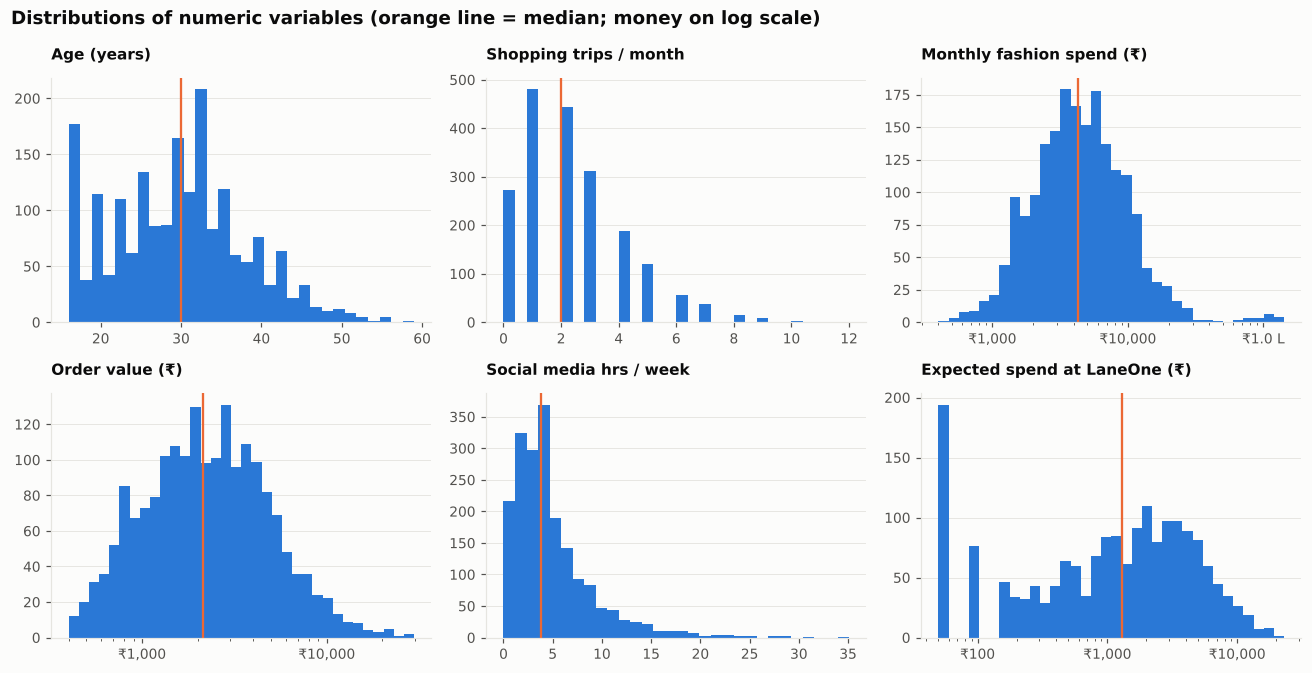

**What:** one histogram per numeric question. **Why:** before modelling we must know each variable's shape, centre and spread. **Insight:** on a log scale, spend and order value look roughly bell-shaped, so a **log transform** makes them suitable for linear models. Shopping frequency is a count piled up at 1–3 trips a month. Social-media time has a long tail (median 4 hrs/week). Expected spend at LaneOne is **bimodal**: a lump near ₹50–200 (people who won't shop) and a second lump at ₹2K–10K (future customers). That two-population shape is the first sign the market splits into buyers and non-buyers.

In [4]:
def d3_distributions(df):
    """Histograms of the six numeric variables (money on log scale)."""
    fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
    for ax, (c, lab) in zip(axes.ravel(), NUM.items()):
        v = df[c].dropna()
        if "₹" in lab:
            v = v[v > 0]
            ax.hist(v, bins=np.logspace(np.log10(v.min()), np.log10(v.max()), 35), color=C.BLUE)
            ax.set_xscale("log"); ax.xaxis.set_major_formatter(C.rupee)
        else:
            ax.hist(v, bins=30, color=C.BLUE)
        ax.axvline(v.median(), color=C.ORANGE, lw=1.5)
        ax.set_title(lab, fontsize=10); ax.grid(axis="x", visible=False)
    fig.suptitle("Distributions of numeric variables (orange line = median; money on log scale)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    social_med = df.Q14_social_hrs_week.median()
    text = ("**What:** one histogram per numeric question. **Why:** before modelling we must know each variable's shape, "
            "centre and spread. **Insight:** on a log scale, spend and order value look roughly bell-shaped, so a "
            "**log transform** makes them suitable for linear models. Shopping frequency is a count piled up at 1–3 "
            f"trips a month. Social-media time has a long tail (median {social_med:.0f} hrs/week). Expected spend "
            "at LaneOne is **bimodal**: a lump near ₹50–200 (people who won't shop) and a second lump at ₹2K–10K "
            "(future customers). That two-population shape is the first sign the market splits into buyers and non-buyers.")
    return {"fig": fig, "table": None, "text": text}

show(d3_distributions(df))

### D4. Categorical profile
Frequency of each categorical answer.

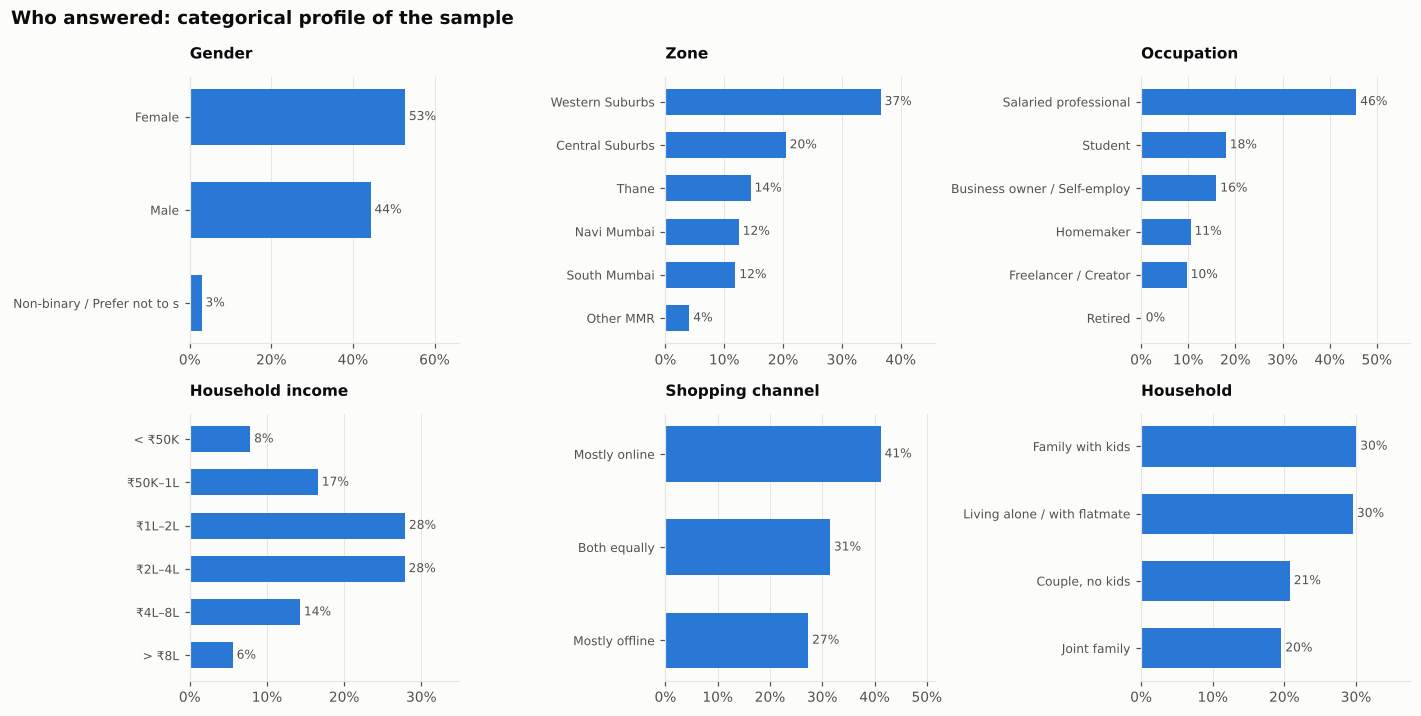

**What:** share of respondents in each category. **Why:** shows whether the sample covers the target market and whether any group is too small to analyse. **Insight:** the sample is led by the Western Suburbs (37%) and salaried professionals (46%), matching an urban, working-age audience. Women are 53%. The non-binary group and 'Other MMR' are small, so results for them should be read with caution.

In [5]:
def d4_categorical(df):
    """Frequency of each categorical answer."""
    cols = {"Q2_gender": "Gender", "Q3_area": "Zone", "Q4_occupation": "Occupation",
            "Q5_household_income": "Household income", "Q10_channel": "Shopping channel", "Q6_household_type": "Household"}
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
    for ax, (c, lab) in zip(axes.ravel(), cols.items()):
        s = df[c].value_counts(normalize=True)
        if c == "Q5_household_income":
            s = s.reindex(INCOME_BANDS)
        s = s.iloc[::-1] if c != "Q5_household_income" else s.iloc[::-1]
        ax.barh([str(i)[:28] for i in s.index], s.values, color=C.BLUE, height=0.6)
        for y, v in enumerate(s.values):
            ax.text(v, y, f" {v:.0%}", va="center", fontsize=8, color=C.INK2)
        ax.xaxis.set_major_formatter(C.pct); ax.set_xlim(0, s.max() * 1.25)
        ax.set_title(lab, fontsize=10); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
    fig.suptitle("Who answered: categorical profile of the sample", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    z = df.Q3_area.value_counts(normalize=True)
    o = df.Q4_occupation.value_counts(normalize=True)
    text = ("**What:** share of respondents in each category. **Why:** shows whether the sample covers the target market and "
            "whether any group is too small to analyse. **Insight:** the sample is led by the "
            f"{z.index[0]} ({z.iloc[0]:.0%}) and {o.index[0].lower()}s ({o.iloc[0]:.0%}), matching an urban, working-age "
            f"audience. Women are {df.Q2_gender.eq('Female').mean():.0%}. The non-binary group and 'Other MMR' are small, "
            "so results for them should be read with caution.")
    return {"fig": fig, "table": None, "text": text}

show(d4_categorical(df))

### D5. Attitude statements (Likert)
Diverging stacked bars of the 10 attitude statements.

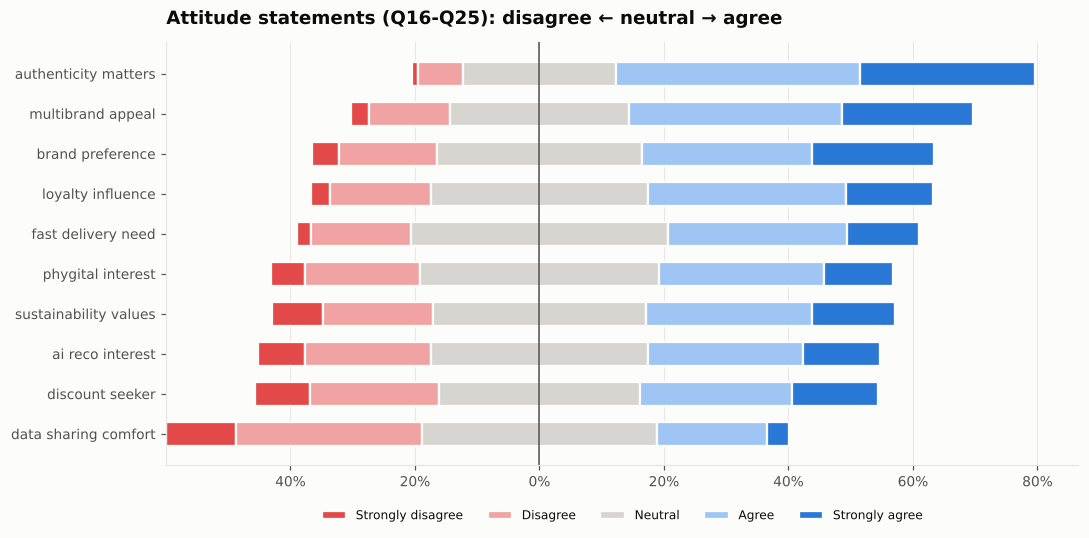

**What:** for each statement, the split from strongly disagree (red) to strongly agree (blue), centred on neutral. **Why:** a diverging bar shows the balance of opinion better than an average. **Insight:** the most agreed statements are **authenticity matters** (67% agree) and **multibrand appeal** (55%). The least agreed is **data sharing comfort** (21%). People want authentic brands but are wary of giving data, so personalisation must be opt-in and visibly useful.

In [6]:
def d5_likert(df):
    """Diverging stacked bars of the 10 attitude statements."""
    order = df[list(LIKERT_COLS)].mean().sort_values().index
    dist = pd.DataFrame({c: df[c].value_counts(normalize=True).reindex([1, 2, 3, 4, 5]).fillna(0) for c in order}).T
    fig, ax = plt.subplots(figsize=(10, 5))
    cols = {1: "#e34948", 2: "#f0a3a2", 3: "#d6d5cf", 4: "#9ec5f4", 5: "#2a78d6"}
    left = -(dist[1] + dist[2] + dist[3] / 2)
    for k in [1, 2, 3, 4, 5]:
        ax.barh([LIK_SHORT[c] for c in dist.index], dist[k], left=left, color=cols[k], label=LIKERT_LABELS[k], height=0.6,
                edgecolor=C.SURFACE, linewidth=1.5)
        left = left + dist[k]
    ax.axvline(0, color=C.INK2, lw=1); ax.xaxis.set_major_formatter(C.FuncFormatter(lambda x, _: f"{abs(x):.0%}"))
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8); ax.grid(axis="y", visible=False)
    ax.set_title("Attitude statements (Q16-Q25): disagree ← neutral → agree")
    fig.tight_layout()
    agree = (df[list(LIKERT_COLS)] >= 4).mean().sort_values(ascending=False)
    text = ("**What:** for each statement, the split from strongly disagree (red) to strongly agree (blue), centred on "
            "neutral. **Why:** a diverging bar shows the balance of opinion better than an average. **Insight:** the most "
            f"agreed statements are **{LIK_SHORT[agree.index[0]]}** ({agree.iloc[0]:.0%} agree) and "
            f"**{LIK_SHORT[agree.index[1]]}** ({agree.iloc[1]:.0%}). The least agreed is **{LIK_SHORT[agree.index[-1]]}** "
            f"({agree.iloc[-1]:.0%}). People want authentic brands but are wary of giving data, so personalisation must be "
            "opt-in and visibly useful.")
    return {"fig": fig, "table": None, "text": text}

show(d5_likert(df))

### D6. Platforms, categories and brands
Platforms used today, categories bought, brands wanted (multi-select shares).

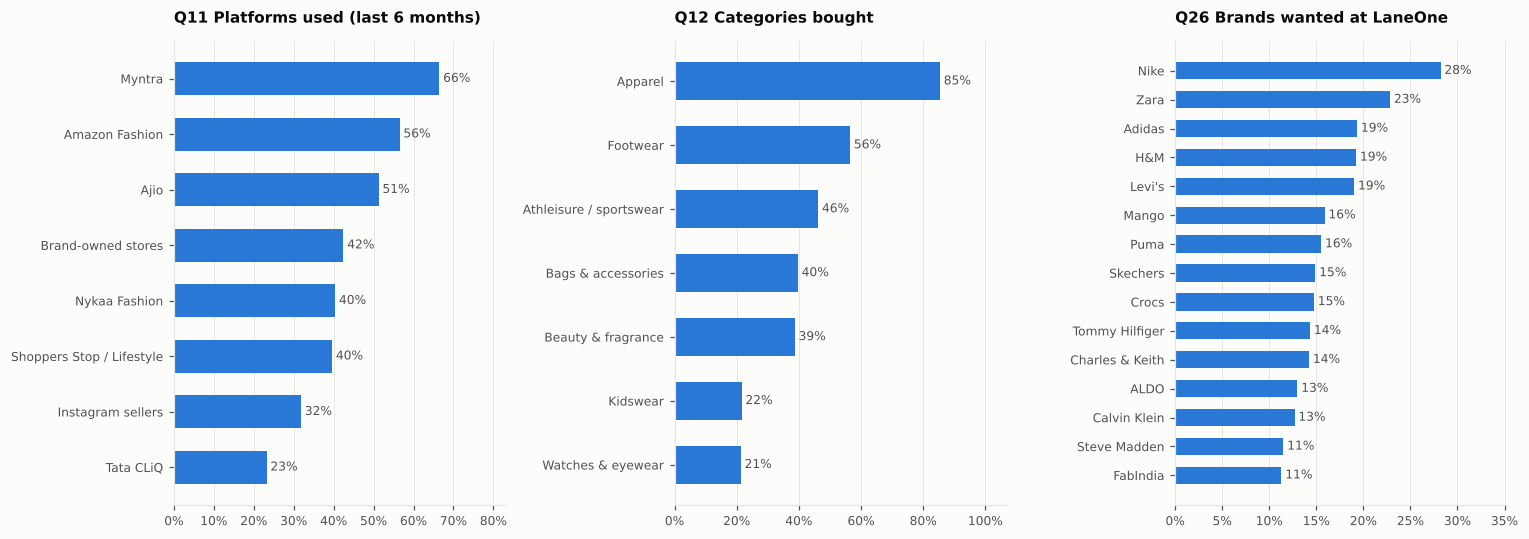

**What:** share of respondents ticking each option. **Why:** multi-select answers show the competitive set, the category mix and brand demand. **Insight:** the main competitors are **Myntra (66%), Amazon Fashion (56%) and Ajio (51%)**. Apparel and footwear are the core categories. **Nike** (28%) and **Zara** (23%) are the most wanted brands. No single brand reaches half the sample, so a multi-brand assortment is needed to serve everyone.

In [7]:
def d6_multiselect(df):
    """Platforms used today, categories bought, brands wanted (multi-select shares)."""
    groups = [("plat_", PLATFORMS, "Q11 Platforms used (last 6 months)"), ("cat_", CATEGORIES, "Q12 Categories bought"),
              ("brand_", BRANDS, "Q26 Brands wanted at LaneOne")]
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    out = {}
    for ax, (p, labels, title) in zip(axes, groups):
        cols = [p + re.sub(r"[^a-z0-9]+", "_", o.lower()).strip("_") for o in labels]
        s = pd.Series(df[cols].mean().values, index=labels).sort_values()
        out[p] = s
        ax.barh(s.index, s.values, color=C.BLUE, height=0.6); ax.xaxis.set_major_formatter(C.pct)
        for y, v in enumerate(s.values):
            ax.text(v, y, f" {v:.0%}", va="center", fontsize=8, color=C.INK2)
        ax.set_xlim(0, s.max() * 1.25); ax.set_title(title, fontsize=10); ax.grid(axis="y", visible=False); ax.tick_params(labelsize=8)
    fig.tight_layout()
    pl, ca, br = out["plat_"], out["cat_"], out["brand_"]
    text = ("**What:** share of respondents ticking each option. **Why:** multi-select answers show the competitive set, "
            "the category mix and brand demand. **Insight:** the main competitors are **"
            f"{pl.index[-1]} ({pl.iloc[-1]:.0%}), {pl.index[-2]} ({pl.iloc[-2]:.0%}) and {pl.index[-3]} ({pl.iloc[-3]:.0%})**. "
            f"{ca.index[-1]} and {ca.index[-2].lower()} are the core categories. **{br.index[-1]}** ({br.iloc[-1]:.0%}) and "
            f"**{br.index[-2]}** ({br.iloc[-2]:.0%}) are the most wanted brands. No single brand reaches half the sample, "
            "so a multi-brand assortment is needed to serve everyone.")
    return {"fig": fig, "table": None, "text": text}

show(d6_multiselect(df))

### D7. The target: purchase intent
The target: purchase-intent distribution and interest by key segments.

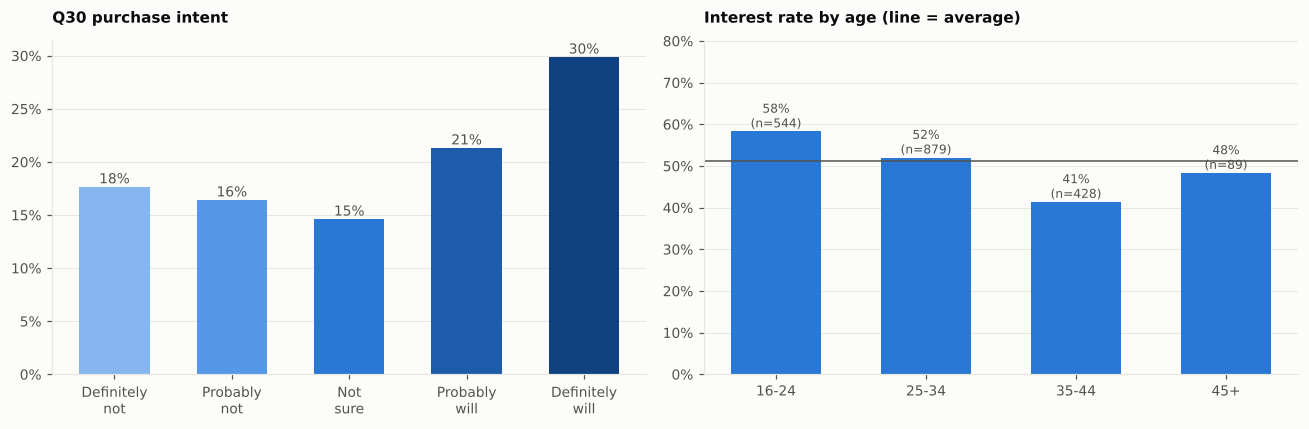

**What:** the target variable and how it varies by age. **Why:** the target's balance decides the modelling approach. **Insight:** 30% say 'Definitely will' and 18% 'Definitely not', with a thin middle: opinions are already formed. Interest peaks at 16–24 (58%) and is lowest at 35–44 (41%). 45–54 and 55+ are merged because only 6 respondents are 55+.

In [8]:
def d7_target(df):
    """The target: purchase-intent distribution and interest by key segments."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    s = df.Q30_purchase_intent.value_counts(normalize=True).reindex(INTENT)
    axes[0].bar([i.replace(" ", "\n") for i in INTENT], s.values, color=C.ORD5, width=0.6)
    for x, v in enumerate(s.values):
        axes[0].text(x, v, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color=C.INK2)
    axes[0].yaxis.set_major_formatter(C.pct); axes[0].grid(axis="x", visible=False); axes[0].set_title("Q30 purchase intent", fontsize=10)
    ag = df.copy(); ag["age_band"] = ag.age_group.replace({"45-54": "45+", "55+": "45+"})
    r = ag.groupby("age_band").interested.agg(["mean", "count"]).reindex(["16-24", "25-34", "35-44", "45+"])
    axes[1].bar(r.index, r["mean"], color=C.BLUE, width=0.6)
    for x, (v, n) in enumerate(zip(r["mean"], r["count"])):
        axes[1].text(x, v, f"{v:.0%}\n(n={n})", ha="center", va="bottom", fontsize=8, color=C.INK2)
    axes[1].axhline(df.interested.mean(), color=C.INK2, lw=1); axes[1].yaxis.set_major_formatter(C.pct)
    axes[1].set_ylim(0, 0.8); axes[1].grid(axis="x", visible=False); axes[1].set_title("Interest rate by age (line = average)", fontsize=10)
    fig.tight_layout()
    text = (f"**What:** the target variable and how it varies by age. **Why:** the target's balance decides the modelling "
            f"approach. **Insight:** {s['Definitely will']:.0%} say 'Definitely will' and {s['Definitely not']:.0%} 'Definitely "
            f"not', with a thin middle: opinions are already formed. Interest peaks at 16–24 ({r.loc['16-24', 'mean']:.0%}) and "
            f"is lowest at 35–44 ({r.loc['35-44', 'mean']:.0%}). 45–54 and 55+ are merged because only "
            f"{(df.age_group == '55+').sum()} respondents are 55+.")
    return {"fig": fig, "table": None, "text": text}

show(d7_target(df))

## Part B — Diagnostic analytics

### G1. Pearson vs Spearman correlation
Pearson vs Spearman correlation matrices side by side.

,age,income ord,log monthly spend,shop freq month,social hrs week,brand preference,authenticity matters,discount seeker,multibrand appeal,ai reco interest,phygital interest,loyalty influence,sustainability values,data sharing comfort,fast delivery need,n brand,intent score,expected monthly spend
age,1.00,0.19,0.10,-0.06,-0.20,0.02,0.00,-0.11,-0.15,-0.20,-0.19,-0.12,-0.02,-0.19,-0.16,-0.08,-0.13,-0.03
income ord,0.19,1.00,0.72,0.15,0.01,0.39,0.35,-0.28,0.12,0.06,0.09,-0.14,0.14,-0.02,0.06,0.13,0.39,0.57
log monthly spend,0.10,0.72,1.00,0.32,0.01,0.55,0.48,-0.30,0.30,0.14,0.23,-0.05,0.10,0.03,0.13,0.35,0.54,0.80
shop freq month,-0.06,0.15,0.32,1.00,0.08,0.33,0.25,-0.13,0.29,0.21,0.27,0.05,-0.01,0.16,0.20,0.28,0.34,0.38
social hrs week,-0.20,0.01,0.01,0.08,1.00,0.02,0.01,-0.01,0.18,0.27,0.23,-0.00,0.03,0.22,0.21,0.01,0.20,0.12
brand preference,0.02,0.39,0.55,0.33,0.02,1.00,0.42,-0.16,0.36,0.13,0.27,0.10,0.09,0.02,0.15,0.35,0.48,0.63
authenticity matters,0.00,0.35,0.48,0.25,0.01,0.42,1.00,-0.12,0.26,0.14,0.20,0.08,0.05,0.01,0.11,0.30,0.44,0.53
discount seeker,-0.11,-0.28,-0.30,-0.13,-0.01,-0.16,-0.12,1.00,-0.07,-0.03,-0.02,0.36,-0.03,-0.01,0.01,-0.06,-0.22,-0.32
multibrand appeal,-0.15,0.12,0.30,0.29,0.18,0.36,0.26,-0.07,1.00,0.36,0.40,0.11,0.03,0.28,0.33,0.31,0.53,0.51
ai reco interest,-0.20,0.06,0.14,0.21,0.27,0.13,0.14,-0.03,0.36,1.00,0.40,0.04,0.02,0.35,0.35,0.14,0.43,0.33


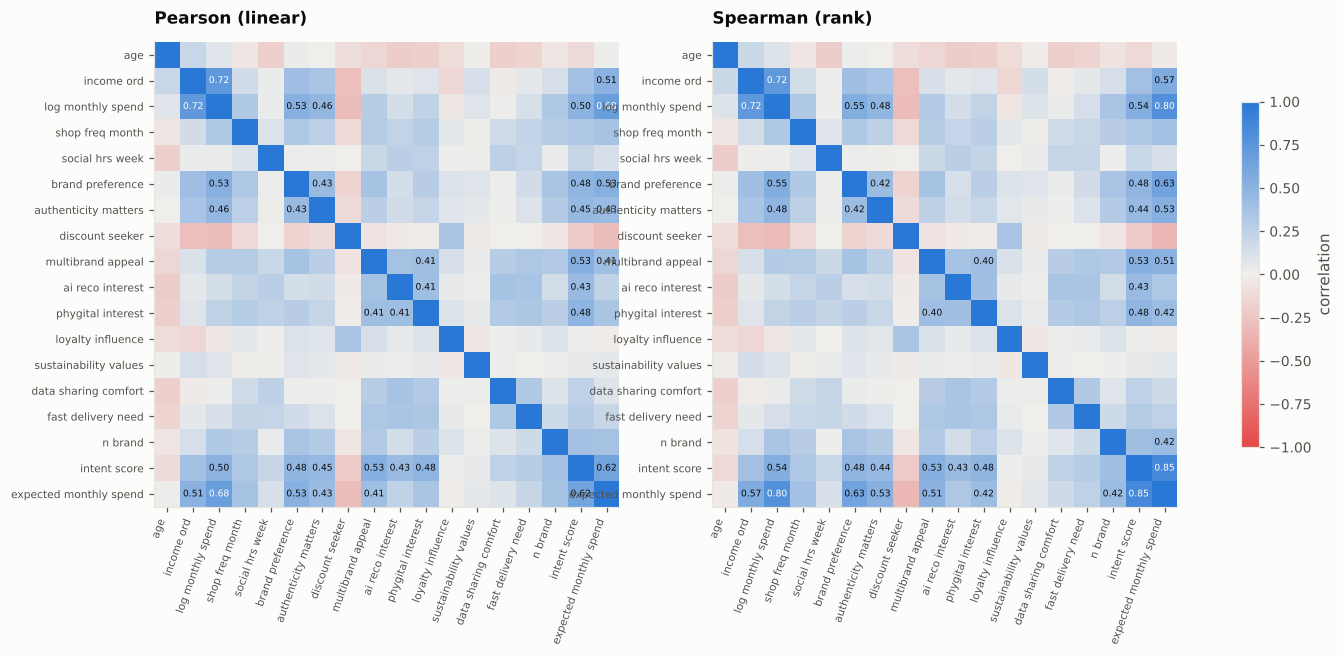

**What:** two correlation matrices of the same 18 variables (labels shown where |r| ≥ 0.4). **Why:** Pearson measures *linear* association and is distorted by skew and outliers; Spearman uses ranks and suits Likert scales and skewed spend. Comparing them shows where the relationships are non-linear. **Insight:** the biggest gap is between **expected monthly spend** and **intent score** (Pearson 0.62 vs Spearman 0.85): raw rupees are skewed, so the relationship is monotonic rather than straight-line. That justifies rank-based diagnostics and a log transform. Intent score and expected spend correlate 0.85, so stated interest and stated spend tell a consistent story.

In [9]:
def g1_pearson_vs_spearman(df):
    """Pearson vs Spearman correlation matrices side by side."""
    d = df[CORR_COLS].dropna()
    pe, sp = d.corr("pearson"), d.corr("spearman")
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
    for ax, m, t in [(axes[0], pe, "Pearson (linear)"), (axes[1], sp, "Spearman (rank)")]:
        im = ax.imshow(m, cmap=C.DIV, vmin=-1, vmax=1); ax.grid(False)
        ax.set_xticks(range(len(m)), [_lab(c) for c in m], rotation=70, ha="right", fontsize=7)
        ax.set_yticks(range(len(m)), [_lab(c) for c in m], fontsize=7); ax.set_title(t, fontsize=11)
        for i in range(len(m)):
            for j in range(len(m)):
                if i != j and abs(m.iat[i, j]) >= 0.4:
                    ax.text(j, i, f"{m.iat[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(m.iat[i, j]) > .65 else C.INK)
    fig.colorbar(im, ax=axes, shrink=0.6, label="correlation")
    diff = (sp - pe).abs().where(~np.eye(len(sp), dtype=bool)).stack().sort_values(ascending=False)
    a, b = diff.index[0]
    text = ("**What:** two correlation matrices of the same 18 variables (labels shown where |r| ≥ 0.4). **Why:** Pearson "
            "measures *linear* association and is distorted by skew and outliers; Spearman uses ranks and suits Likert "
            "scales and skewed spend. Comparing them shows where the relationships are non-linear. **Insight:** the "
            f"biggest gap is between **{_lab(a)}** and **{_lab(b)}** (Pearson {pe.loc[a, b]:.2f} vs Spearman "
            f"{sp.loc[a, b]:.2f}): raw rupees are skewed, so the relationship is monotonic rather than straight-line. That "
            f"justifies rank-based diagnostics and a log transform. Intent score and expected spend correlate "
            f"{sp.loc['intent_score', 'Q28_expected_monthly_spend']:.2f}, so stated interest and stated spend tell a "
            "consistent story.")
    return {"fig": fig, "table": sp.round(2).rename(index=_lab, columns=_lab), "text": text}

show(g1_pearson_vs_spearman(df))

### G2. What moves with purchase interest?
Which variables move with purchase interest? Ranked correlation with the target.

,variable,Spearman ρ,point-biserial r,p-value
0,discount seeker,-0.186,-0.184,0.000
1,age,-0.114,-0.100,0.000
2,loyalty influence,-0.007,-0.009,0.770
3,sustainability values,0.037,0.036,0.105
4,social hrs week,0.167,0.181,0.000
5,n plat,0.207,0.208,0.000
6,core zone,0.210,0.210,0.000
7,data sharing comfort,0.218,0.217,0.000
8,fast delivery need,0.250,0.251,0.000
9,shop freq month,0.282,0.287,0.000


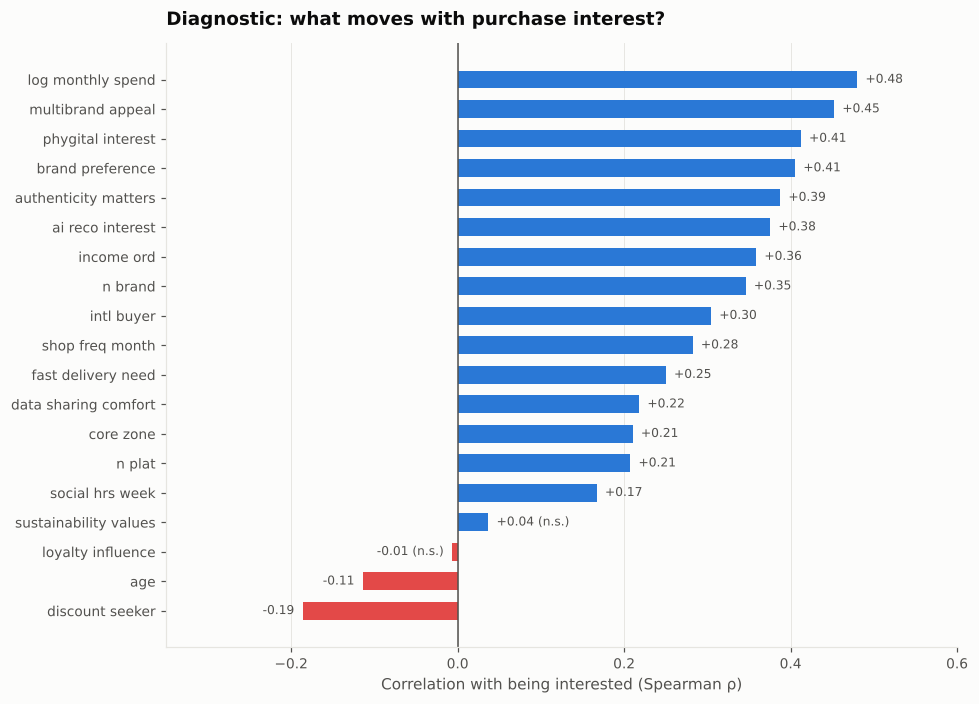

**What:** each variable's correlation with the 0/1 target (blue = higher interest, red = lower; n.s. = not significant at 5%). **Why:** it ranks the candidate drivers before any model is built, and the point-biserial column confirms the same ordering with the classic binary-vs-numeric measure. **Insight:** the strongest positive drivers are **log monthly spend** (ρ 0.48), **multibrand appeal** (0.45) and **phygital interest** (0.41). **discount seeker** pulls the other way (-0.19). No meaningful link: loyalty influence, sustainability values. Interest is driven by spending power and the concept's pillars (multi-brand, phygital, AI), not by demographics alone.

In [10]:
def g2_drivers_of_interest(df):
    """Which variables move with purchase interest? Ranked correlation with the target."""
    cols = [c for c in CORR_COLS if c not in ("intent_score", "Q28_expected_monthly_spend")] + ["intl_buyer", "core_zone", "n_plat"]
    rows = []
    for c in cols:
        rho, p = stats.spearmanr(df[c], df.interested)
        pb, _ = stats.pointbiserialr(df.interested, df[c])
        rows.append({"variable": _lab(c), "Spearman ρ": rho, "point-biserial r": pb, "p-value": p})
    t = pd.DataFrame(rows).sort_values("Spearman ρ").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.barh(t.variable, t["Spearman ρ"], color=[C.CAT[7] if v < 0 else C.BLUE for v in t["Spearman ρ"]], height=0.6)
    for y, (v, p) in enumerate(zip(t["Spearman ρ"], t["p-value"])):
        ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:+.2f}{'' if p < 0.05 else ' (n.s.)'}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, color=C.INK2)
    ax.axvline(0, color=C.INK2, lw=1); ax.grid(axis="y", visible=False); ax.set_xlim(-0.35, 0.6)
    ax.set_xlabel("Correlation with being interested (Spearman ρ)"); ax.set_title("Diagnostic: what moves with purchase interest?")
    fig.tight_layout()
    top = t.sort_values("Spearman ρ", ascending=False)
    ns = t[t["p-value"] >= 0.05].variable.tolist()
    text = ("**What:** each variable's correlation with the 0/1 target (blue = higher interest, red = lower; n.s. = not "
            "significant at 5%). **Why:** it ranks the candidate drivers before any model is built, and the point-biserial "
            "column confirms the same ordering with the classic binary-vs-numeric measure. **Insight:** the strongest "
            f"positive drivers are **{top.variable.iloc[0]}** (ρ {top['Spearman ρ'].iloc[0]:.2f}), **{top.variable.iloc[1]}** "
            f"({top['Spearman ρ'].iloc[1]:.2f}) and **{top.variable.iloc[2]}** ({top['Spearman ρ'].iloc[2]:.2f}). "
            f"**{t.variable.iloc[0]}** pulls the other way ({t['Spearman ρ'].iloc[0]:.2f}). "
            + (f"No meaningful link: {', '.join(ns)}. " if ns else "")
            + "Interest is driven by spending power and the concept's pillars (multi-brand, phygital, AI), not by demographics alone.")
    return {"fig": fig, "table": t.round(3), "text": text}

show(g2_drivers_of_interest(df))

### G3. Categorical associations (Cramér's V)
Association between categorical variables (Cramér's V).

,gender,zone,occupation,income,household,channel,attraction driver,INTERESTED
gender,1.00,0.08,0.05,0.05,0.03,0.04,0.06,0.06
zone,0.08,1.00,0.04,0.17,0.06,0.04,0.06,0.24
occupation,0.05,0.04,1.00,0.13,0.19,0.13,0.06,0.06
income,0.05,0.17,0.13,1.00,0.09,0.04,0.08,0.36
household,0.03,0.06,0.19,0.09,1.00,0.06,0.05,0.04
channel,0.04,0.04,0.13,0.04,0.06,1.00,0.10,0.29
attraction driver,0.06,0.06,0.06,0.08,0.05,0.10,1.00,0.16
INTERESTED,0.06,0.24,0.06,0.36,0.04,0.29,0.16,1.00


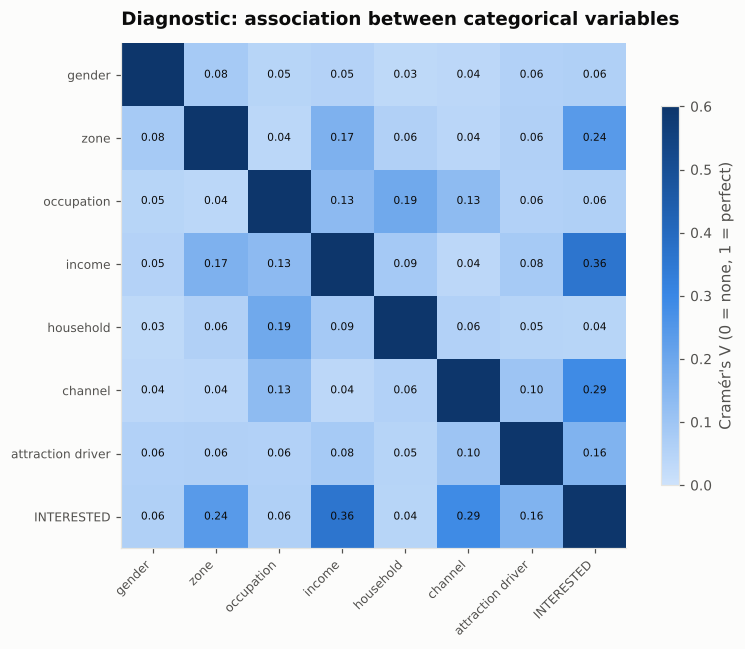

**What:** Cramér's V for every pair of categorical variables (a chi-square-based 0–1 strength measure). **Why:** Pearson/Spearman can't be used on unordered categories, but we still need to know which categories relate to interest and to each other. **Insight:** interest is most associated with **income** (V = 0.36), **channel** (0.29) and **zone** (0.24); **household** barely matters (0.04). Zone and income are themselves related (V = 0.17), because richer households cluster in South Mumbai and the Western Suburbs. Part of the zone effect is therefore really an income effect, which the drill-down below checks.

In [11]:
def g3_cramers_v(df):
    """Association between categorical variables (Cramér's V)."""
    cols = {"Q2_gender": "gender", "Q3_area": "zone", "Q4_occupation": "occupation", "Q5_household_income": "income",
            "Q6_household_type": "household", "Q10_channel": "channel", "Q27_attraction_driver": "attraction driver",
            "persona_true": None, "interested": "INTERESTED"}
    cols = {k: v for k, v in cols.items() if v and k in df.columns}
    keys = list(cols)
    m = pd.DataFrame([[_cramers_v(df[a], df[b]) if a != b else 1.0 for b in keys] for a in keys],
                     index=[cols[k] for k in keys], columns=[cols[k] for k in keys])
    fig, ax = plt.subplots(figsize=(7.5, 6))
    im = ax.imshow(m, cmap=C.SEQMAP, vmin=0, vmax=0.6); ax.grid(False)
    ax.set_xticks(range(len(m)), m.columns, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(len(m)), m.index, fontsize=8)
    for i in range(len(m)):
        for j in range(len(m)):
            if i != j:
                ax.text(j, i, f"{m.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if m.iat[i, j] > .4 else C.INK)
    fig.colorbar(im, ax=ax, shrink=0.75, label="Cramér's V (0 = none, 1 = perfect)")
    ax.set_title("Diagnostic: association between categorical variables"); fig.tight_layout()
    tgt = m["INTERESTED"].drop("INTERESTED").sort_values(ascending=False)
    text = ("**What:** Cramér's V for every pair of categorical variables (a chi-square-based 0–1 strength measure). "
            "**Why:** Pearson/Spearman can't be used on unordered categories, but we still need to know which categories "
            "relate to interest and to each other. **Insight:** interest is most associated with **"
            f"{tgt.index[0]}** (V = {tgt.iloc[0]:.2f}), **{tgt.index[1]}** ({tgt.iloc[1]:.2f}) and **{tgt.index[2]}** "
            f"({tgt.iloc[2]:.2f}); **{tgt.index[-1]}** barely matters ({tgt.iloc[-1]:.2f}). Zone and income are themselves "
            f"related (V = {m.loc['zone', 'income']:.2f}), because richer households cluster in South Mumbai and the Western "
            "Suburbs. Part of the zone effect is therefore really an income effect, which the drill-down below checks.")
    return {"fig": fig, "table": m.round(2), "text": text}

show(g3_cramers_v(df))

### G4. Drill-down: zone vs income
Drill-down: is the zone effect real, or just income? Interest by zone × income tier.

income_tier,< ₹1L,₹1L–4L,> ₹4L
Q3_area,,,
South Mumbai,NaN,67.0,80.0
Western Suburbs,28.0,59.0,82.0
Central Suburbs,29.0,50.0,65.0
Thane,23.0,42.0,69.0
Navi Mumbai,36.0,42.0,64.0
Other MMR,12.0,24.0,NaN


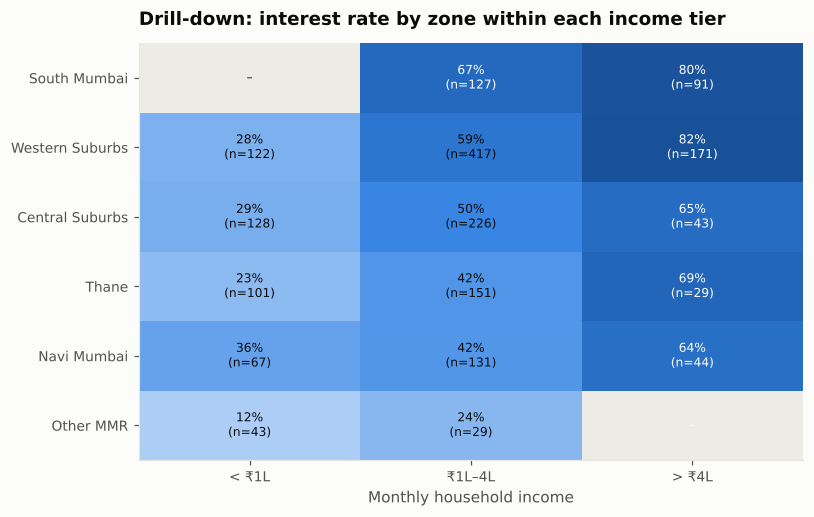

**What:** interest rate for each zone *within* the same income tier (cells with fewer than 15 people hidden). **Why:** a diagnostic drill-down separates two confounded drivers. If zone only mattered through income, each column would look flat. **Insight:** interest rises left to right in every zone, so **income is the dominant driver**. But zone still matters inside the same income tier: among > ₹4L households, Western Suburbs reaches 82% vs Navi Mumbai 64%. Location and income both count, which supports a Western-Suburbs store targeting ₹1L+ households.

In [12]:
def g4_zone_income_drilldown(df):
    """Drill-down: is the zone effect real, or just income? Interest by zone × income tier."""
    d = df.copy()
    d["income_tier"] = pd.cut(d.income_ord, [-1, 1, 3, 5], labels=["< ₹1L", "₹1L–4L", "> ₹4L"])
    t = d.pivot_table(index="Q3_area", columns="income_tier", values="interested", aggfunc="mean", observed=False).reindex(AREAS)
    n = d.pivot_table(index="Q3_area", columns="income_tier", values="interested", aggfunc="count", observed=False).reindex(AREAS)
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    cmap = C.SEQMAP.copy(); cmap.set_bad("#ecebe6")
    ax.imshow(np.ma.masked_invalid(t.where(n >= 15).values.astype(float)), cmap=cmap, vmin=0, vmax=1, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(t.shape[1]), [str(c) for c in t.columns]); ax.set_yticks(range(t.shape[0]), t.index)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v, k = t.iat[i, j], n.iat[i, j]
            ax.text(j, i, "–" if pd.isna(v) or k < 15 else f"{v:.0%}\n(n={int(k)})", ha="center", va="center", fontsize=8,
                    color="white" if (not pd.isna(v) and v > .6) else C.INK)
    ax.set_xlabel("Monthly household income"); ax.set_title("Drill-down: interest rate by zone within each income tier")
    fig.tight_layout()
    hi = t["> ₹4L"]
    text = ("**What:** interest rate for each zone *within* the same income tier (cells with fewer than 15 people hidden). "
            "**Why:** a diagnostic drill-down separates two confounded drivers. If zone only mattered through income, each "
            "column would look flat. **Insight:** interest rises left to right in every zone, so **income is the dominant "
            "driver**. But zone still matters inside the same income tier: among > ₹4L households, "
            f"{hi.idxmax()} reaches {hi.max():.0%} vs {hi.dropna().idxmin()} {hi.dropna().min():.0%}. Location and income "
            "both count, which supports a Western-Suburbs store targeting ₹1L+ households.")
    return {"fig": fig, "table": (t.where(n >= 15) * 100).round(0), "text": text}

show(g4_zone_income_drilldown(df))

### G5. Income → spend → LaneOne spend
Scatter diagnostics: income → current spend → expected spend.

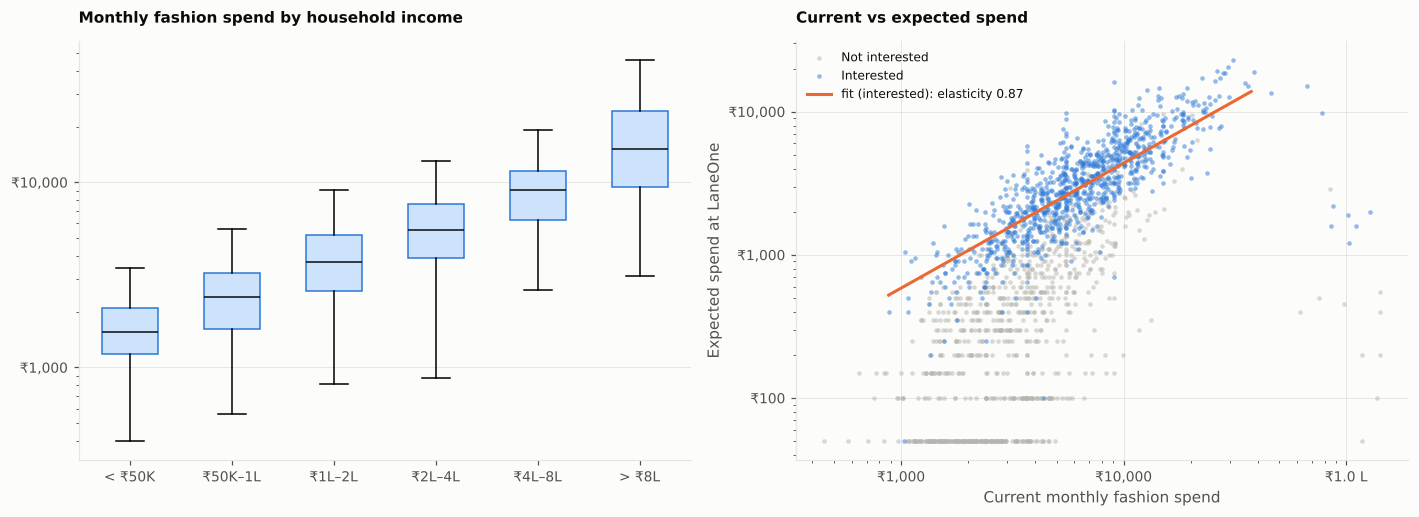

**What:** left, spend by income band (box = middle 50%, line = median); right, current vs expected spend with a log-log fit for interested respondents. **Why:** it traces the chain *income → fashion budget → LaneOne spend*, which is the logic behind the revenue forecast. **Insight:** median spend rises from ₹1,560 (< ₹50K) to ₹15,090 (> ₹8L). The fitted elasticity of **0.87** means a 10% bigger fashion budget brings about 9% more expected spend with us. Interested people expect to move a median **48% of their current fashion budget** to LaneOne, a realistic share-of-wallet target.

In [13]:
def g5_spend_relationships(df):
    """Scatter diagnostics: income → current spend → expected spend."""
    d = df.dropna(subset=["Q28_expected_monthly_spend"])
    d = d[(d.Q28_expected_monthly_spend > 0) & (d.Q9_monthly_fashion_spend > 0)]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    g = df.groupby("Q5_household_income").Q9_monthly_fashion_spend
    data = [df.loc[df.Q5_household_income == b, "Q9_monthly_fashion_spend"] for b in INCOME_BANDS]
    axes[0].boxplot(data, tick_labels=INCOME_BANDS, showfliers=False, patch_artist=True, widths=0.55,
                    boxprops=dict(facecolor="#cde2fb", color=C.BLUE), medianprops=dict(color=C.INK))
    axes[0].set_yscale("log"); axes[0].yaxis.set_major_formatter(C.rupee); axes[0].grid(axis="x", visible=False)
    axes[0].set_title("Monthly fashion spend by household income", fontsize=10)
    for k, col, lab in [(0, C.GREY, "Not interested"), (1, C.BLUE, "Interested")]:
        s = d[d.interested == k]
        axes[1].scatter(s.Q9_monthly_fashion_spend, s.Q28_expected_monthly_spend, s=9, alpha=.5, color=col, label=lab, linewidths=0)
    s1 = d[d.interested == 1]
    b, a = np.polyfit(np.log10(s1.Q9_monthly_fashion_spend), np.log10(s1.Q28_expected_monthly_spend), 1)
    xs = np.logspace(np.log10(s1.Q9_monthly_fashion_spend.min()), np.log10(s1.Q9_monthly_fashion_spend.quantile(.99)), 50)
    axes[1].plot(xs, 10 ** a * xs ** b, color=C.ORANGE, lw=2, label=f"fit (interested): elasticity {b:.2f}")
    axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].xaxis.set_major_formatter(C.rupee); axes[1].yaxis.set_major_formatter(C.rupee)
    axes[1].set_xlabel("Current monthly fashion spend"); axes[1].set_ylabel("Expected spend at LaneOne"); axes[1].legend(fontsize=8)
    axes[1].set_title("Current vs expected spend", fontsize=10)
    fig.tight_layout()
    meds = g.median().reindex(INCOME_BANDS)
    share = (s1.Q28_expected_monthly_spend / s1.Q9_monthly_fashion_spend).median()
    text = ("**What:** left, spend by income band (box = middle 50%, line = median); right, current vs expected spend "
            "with a log-log fit for interested respondents. **Why:** it traces the chain *income → fashion budget → "
            "LaneOne spend*, which is the logic behind the revenue forecast. **Insight:** median spend rises from "
            f"₹{meds.iloc[0]:,.0f} (< ₹50K) to ₹{meds.iloc[-1]:,.0f} (> ₹8L). The fitted elasticity of **{b:.2f}** means a "
            f"10% bigger fashion budget brings about {b * 10:.0f}% more expected spend with us. Interested people expect to "
            f"move a median **{share:.0%} of their current fashion budget** to LaneOne, a realistic share-of-wallet target.")
    return {"fig": fig, "table": None, "text": text}

show(g5_spend_relationships(df))

### G6. Dose-response: attitudes by intent level
Mean attitude score at each of the 5 intent levels (dose-response check).

,brand preference,authenticity matters,discount seeker,multibrand appeal,ai reco interest,phygital interest,loyalty influence,sustainability values,data sharing comfort,fast delivery need
Q30_purchase_intent,,,,,,,,,,
Definitely not,2.53,3.16,3.48,2.71,2.46,2.39,3.34,3.04,2.33,2.92
Probably not,3.06,3.59,3.41,3.18,2.76,2.87,3.43,3.28,2.56,3.08
Not sure,3.36,3.77,3.14,3.44,2.98,3.06,3.37,3.13,2.64,3.24
Probably will,3.57,4.05,3.12,3.70,3.23,3.31,3.33,3.20,2.80,3.36
Definitely will,4.07,4.33,2.79,4.28,3.78,3.83,3.39,3.25,3.03,3.68


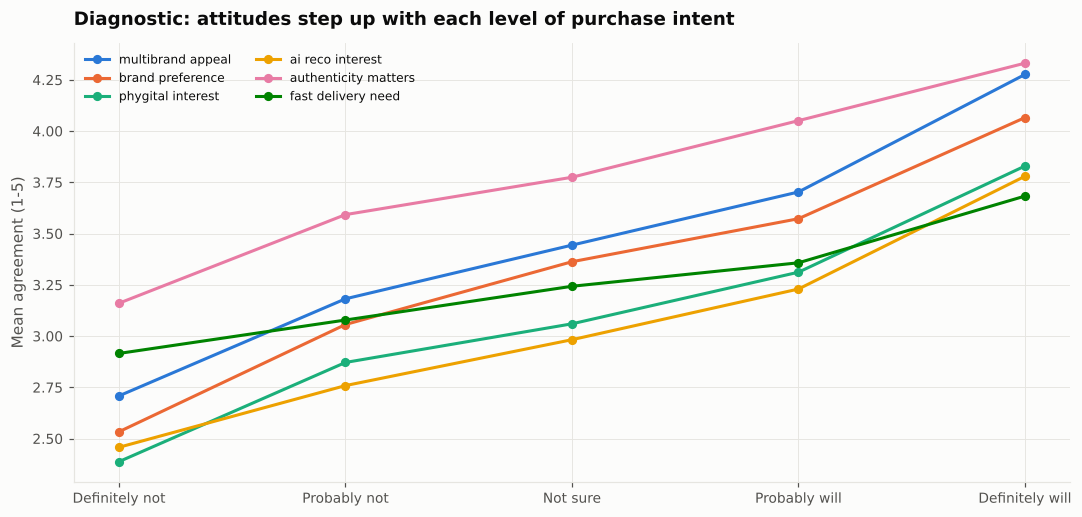

**What:** average agreement with the six most discriminating statements at each intent level. **Why:** a *dose-response* pattern (scores rising step by step from 'Definitely not' to 'Definitely will') is stronger diagnostic evidence than a simple yes/no gap, because it rules out a one-off difference. **Insight:** **multibrand appeal** climbs from 2.71 to 4.28. 7 of 10 attitudes rise monotonically with intent. Discount-seeking moves the opposite way: the more someone wants LaneOne, the less they are driven by sales. That is good news for margins.

In [14]:
def g6_attitudes_by_intent(df):
    """Mean attitude score at each of the 5 intent levels (dose-response check)."""
    m = df.groupby("Q30_purchase_intent")[list(LIKERT_COLS)].mean().reindex(INTENT)
    keep = (m.iloc[-1] - m.iloc[0]).abs().sort_values(ascending=False).index[:6]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    for i, c in enumerate(keep):
        ax.plot(range(5), m[c], marker="o", ms=5, color=C.CAT[i], label=LIK_SHORT[c])
    ax.set_xticks(range(5), INTENT); ax.set_ylabel("Mean agreement (1-5)"); ax.legend(fontsize=8, ncol=2)
    ax.set_title("Diagnostic: attitudes step up with each level of purchase intent")
    fig.tight_layout()
    mono = [c for c in LIKERT_COLS if m[c].is_monotonic_increasing]
    c0 = keep[0]
    text = ("**What:** average agreement with the six most discriminating statements at each intent level. **Why:** a "
            "*dose-response* pattern (scores rising step by step from 'Definitely not' to 'Definitely will') is stronger "
            "diagnostic evidence than a simple yes/no gap, because it rules out a one-off difference. **Insight:** "
            f"**{LIK_SHORT[c0]}** climbs from {m[c0].iloc[0]:.2f} to {m[c0].iloc[-1]:.2f}. {len(mono)} of 10 attitudes rise "
            "monotonically with intent. Discount-seeking moves the opposite way: the more someone wants LaneOne, the less "
            "they are driven by sales. That is good news for margins.")
    return {"fig": fig, "table": m.round(2).rename(columns=LIK_SHORT), "text": text}

show(g6_attitudes_by_intent(df))

### G7. Hypothesis tests with effect sizes
Hypothesis tests with effect sizes (not just p-values).

In [15]:
def g7_hypothesis_effects(df):
    """Hypothesis tests with effect sizes (not just p-values)."""
    import analytics as A
    h = A.hypothesis_tests(df)
    eff = []
    n = len(df)
    for _, r in h.iterrows():
        test = r["Test"]
        if "Chi" in test:
            col = {"H1": "Q5_household_income", "H6": "Q3_area", "H10": "Q10_channel"}.get(r["H"])
            v = _cramers_v(df[col], df.interested) if col else _cramers_v(df.Q1_age <= 34, df.interested)
            eff.append((f"Cramér's V = {v:.2f}", "small" if v < .2 else "medium" if v < .4 else "large"))
        elif "Mann" in test:
            u = r["Statistic"]
            if r["H"] == "H11":
                n1, n2 = df.Q2_gender.eq("Female").sum(), df.Q2_gender.eq("Male").sum()
            else:
                n1, n2 = df.interested.sum(), (1 - df.interested).sum()
            rb = 2 * u / (n1 * n2) - 1
            eff.append((f"rank-biserial = {rb:.2f}", "small" if abs(rb) < .3 else "medium" if abs(rb) < .5 else "large"))
        elif "Spearman" in test:
            v = r["Statistic"]
            eff.append((f"ρ = {v:.2f}", "small" if abs(v) < .3 else "medium" if abs(v) < .5 else "large"))
        else:
            eps = r["Statistic"] / (n - 1)
            eff.append((f"ε² = {eps:.3f}", "negligible" if eps < .01 else "small"))
    h["Effect size"] = [e[0] for e in eff]
    h["Magnitude"] = [e[1] for e in eff]
    t = h[["H", "Hypothesis (H1 / alternative)", "Test", "p-value", "Effect size", "Magnitude", "Decision"]]
    big = t[t.Magnitude == "large"].H.tolist()
    text = ("**What:** the 11 business hypotheses with p-values *and* effect sizes. **Why:** with ~1,900 respondents almost "
            "any difference becomes 'significant', so effect size tells us whether it matters commercially. **Insight:** "
            f"large effects ({', '.join(big)}) are the ones to build strategy on: current spend (H3), multi-brand appeal (H4) "
            "and the current-to-expected spend link (H8). Income (H1), AI interest (H5) and zone (H6) are medium. H11 (gender) is significant but small, so it informs the assortment mix, not targeting. "
            "H9 (sustainability by age) is not supported, so sustainability messaging should go to all ages.")
    return {"fig": None, "table": t, "text": text}

show(g7_hypothesis_effects(df))

,H,Hypothesis (H1 / alternative),Test,p-value,Effect size,Magnitude,Decision
0,H1,Interest differs across household-income bands,Chi-square,4.74e-52,Cramér's V = 0.36,medium,Reject H0 ✔ (supported)
1,H2,Under-35s are more interested than 35+,Chi-square (2×2),5.09e-06,Cramér's V = 0.10,small,Reject H0 ✔ (supported)
2,H3,Interested respondents already spend more on fashion,Mann-Whitney U (one-sided),1.86e-99,rank-biserial = 0.55,large,Reject H0 ✔ (supported)
3,H4,'Many brands under one roof' appeal is higher among the interested,Mann-Whitney U (one-sided),1.66e-88,rank-biserial = 0.50,large,Reject H0 ✔ (supported)
4,H5,Interest in AI recommendations correlates with purchase intent,Spearman ρ,1.64e-88,ρ = 0.43,medium,Reject H0 ✔ (supported)
5,H6,Interest differs by Mumbai zone,Chi-square,1.48e-22,Cramér's V = 0.24,medium,Reject H0 ✔ (supported)
6,H7,Discount-seekers show lower purchase intent,Spearman ρ,2.61e-23,ρ = -0.22,small,Reject H0 ✔ (supported)
7,H8,Expected spend at us rises with current fashion spend,Spearman ρ,0.00e+00,ρ = 0.80,large,Reject H0 ✔ (supported)
8,H9,Sustainability values differ by age group,Kruskal-Wallis H,0.307,ε² = 0.002,negligible,Fail to reject H0 ✘
9,H10,Interest differs between online-first and offline-first shoppers,Chi-square,1.88e-35,Cramér's V = 0.29,medium,Reject H0 ✔ (supported)


**What:** the 11 business hypotheses with p-values *and* effect sizes. **Why:** with ~1,900 respondents almost any difference becomes 'significant', so effect size tells us whether it matters commercially. **Insight:** large effects (H3, H4, H8) are the ones to build strategy on: current spend (H3), multi-brand appeal (H4) and the current-to-expected spend link (H8). Income (H1), AI interest (H5) and zone (H6) are medium. H11 (gender) is significant but small, so it informs the assortment mix, not targeting. H9 (sustainability by age) is not supported, so sustainability messaging should go to all ages.

### G8. Outliers and multicollinearity
Remaining outliers (IQR rule) and multicollinearity (VIF) among model predictors.

,variable,IQR outliers,share,scale
0,Age (years),12,0.6%,raw
1,Shopping trips / month,65,3.4%,raw
2,Monthly fashion spend (₹),25,1.3%,log
3,Order value (₹),5,0.3%,log
4,Social media hrs / week,121,6.2%,raw
5,Expected spend at LaneOne (₹),47,2.5%,log


,predictor,VIF
2,log monthly spend,3.36
1,income ord,2.36
4,avg order value,2.02
3,shop freq month,1.91
6,brand preference,1.65
9,multibrand appeal,1.50
11,phygital interest,1.48
10,ai reco interest,1.45
7,authenticity matters,1.39
14,data sharing comfort,1.30


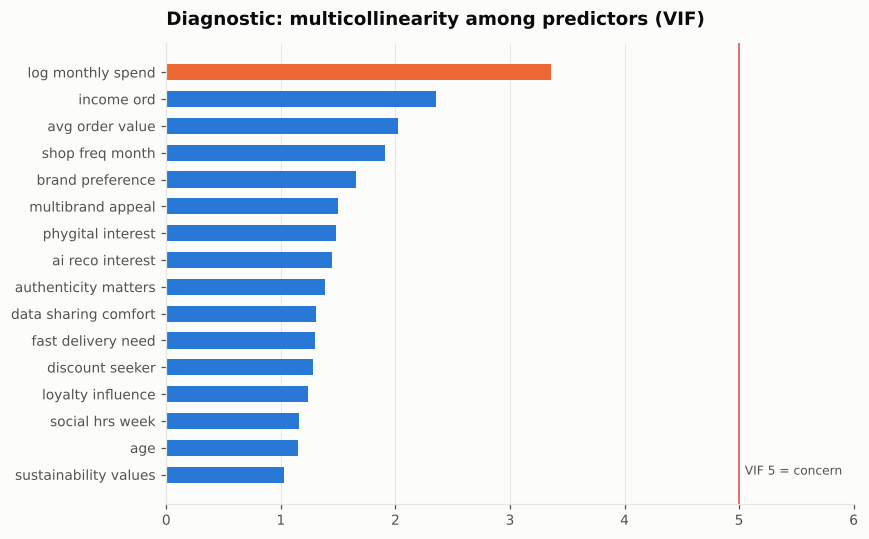

**What:** the table counts values still outside 1.5×IQR after cleaning (money on log scale); the chart shows each predictor's variance inflation factor. **Why:** outliers that survive cleaning should be *genuine*, and highly inter-correlated predictors make regression coefficients unstable. **Insight:** 275 statistical outliers remain (6.2% at most per variable). They are real heavy shoppers and frequent social users, so they were kept. The highest VIF is **log monthly spend (3.4)**, well below 5, so multicollinearity is not a problem, though income and spend overlap enough that Ridge/Lasso were tried alongside plain linear regression.

In [16]:
def g8_outliers_multicollinearity(df):
    """Remaining outliers (IQR rule) and multicollinearity (VIF) among model predictors."""
    rows = []
    for c, lab in NUM.items():
        v = df[c].dropna()
        x = np.log1p(v) if "₹" in lab else v
        q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
        o = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
        rows.append({"variable": lab, "IQR outliers": int(o), "share": o / len(v), "scale": "log" if "₹" in lab else "raw"})
    out = pd.DataFrame(rows)
    X = df[["Q1_age", "income_ord", "log_monthly_spend", "Q8_shop_freq_month", "Q13_avg_order_value", "Q14_social_hrs_week",
            *LIKERT_COLS]].astype(float)
    X = (X - X.mean()) / X.std()
    vif = []
    for c in X.columns:
        y = X[c].values; Z = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        beta, *_ = np.linalg.lstsq(Z, y, rcond=None)
        r2 = 1 - ((y - Z @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        vif.append({"predictor": _lab(c), "VIF": 1 / (1 - r2)})
    vif = pd.DataFrame(vif).sort_values("VIF", ascending=False)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(vif.predictor[::-1], vif.VIF[::-1], color=[C.ORANGE if v > 2.5 else C.BLUE for v in vif.VIF[::-1]], height=0.6)
    ax.axvline(5, color=C.CAT[7], lw=1); ax.text(5.05, 0, "VIF 5 = concern", color=C.INK2, fontsize=8)
    ax.set_xlim(0, max(6, vif.VIF.max() * 1.1)); ax.grid(axis="y", visible=False)
    ax.set_title("Diagnostic: multicollinearity among predictors (VIF)"); fig.tight_layout()
    text = ("**What:** the table counts values still outside 1.5×IQR after cleaning (money on log scale); the chart shows "
            "each predictor's variance inflation factor. **Why:** outliers that survive cleaning should be *genuine*, and "
            "highly inter-correlated predictors make regression coefficients unstable. **Insight:** "
            f"{out['IQR outliers'].sum()} statistical outliers remain ({out.share.max():.1%} at most per variable). They "
            "are real heavy shoppers and frequent social users, so they were kept. The highest VIF is "
            f"**{vif.predictor.iloc[0]} ({vif.VIF.iloc[0]:.1f})**, well below 5, so multicollinearity is not a problem, though "
            "income and spend overlap enough that Ridge/Lasso were tried alongside plain linear regression.")
    return {"fig": fig, "table": out.assign(share=out.share.map(lambda x: f"{x:.1%}")), "text": text, "table2": vif.round(2)}

show(g8_outliers_multicollinearity(df))

## Summary of insights
**Descriptive**
* Young, urban, working-age sample (median age 30); 46% salaried; Western Suburbs largest zone.
* Spend variables are heavily right-skewed, so medians and log transforms are used throughout.
* 51% interested; answers are polarised (few 'Not sure').
* Authenticity is the most agreed attitude; data-sharing comfort the least.
* Myntra, Amazon and Ajio are the incumbents; no brand is wanted by more than ~28%, so a multi-brand assortment is needed.

**Diagnostic**
* Interest is driven by **spending power** (current spend, income) and the **concept pillars** (multi-brand appeal,
  phygital, AI recommendations, authenticity). Discount-seeking and age pull it down.
* Income is the dominant categorical driver; zone adds an effect *within* the same income tier.
* Attitudes rise step by step with intent (dose-response), so the relationship is consistent, not a one-off gap.
* The largest effect sizes: current spend, multi-brand appeal and the spend link. Gender is significant but small.
* Remaining outliers are genuine and multicollinearity is low (all VIF < 5).

**Strategic implication:** target ₹1L+ households in the Western Suburbs and South Mumbai, lead with authenticity and
multi-brand discovery (not discounts), and make personalisation opt-in.